# Customer Churn Prediction — Project
**Student:** Akash Ranjan | **Enrollment:** A357192625003  
**Program:** B.Tech CSE (AI & DS), Batch 2025–2029  
**Institution:** Amity University Jharkhand, Ranchi  
**Faculty Guide:** Mr. Saikat Mondal

This notebook loads a public GitHub-hosted copy of the IBM Telco Customer Churn sample, performs EDA, prepares the data, compares two classifiers, evaluates results, and exports the selected model pipeline. Run all cells in order. Use actual outputs in your report; do not invent metrics. Verify the dataset's provenance and terms before submission.

## 1. Install required libraries

In [ ]:
%pip -q install pandas numpy scikit-learn matplotlib seaborn joblib requests


## 2. Import libraries

In [ ]:
import io, json, requests
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, ConfusionMatrixDisplay, RocCurveDisplay)

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")
print("Libraries loaded including extra algorithms.")

Libraries loaded including extra algorithms.


## 3. Load dataset
This uses a GitHub-hosted copy of the commonly used IBM Telco Customer Churn sample. If download fails, upload the CSV into Colab and set `CSV_PATH` to its location.

In [ ]:
DATA_URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
CSV_PATH = None  # e.g. "/content/Telco-Customer-Churn.csv" after uploading

try:
    response = requests.get(DATA_URL, timeout=30)
    response.raise_for_status()
    df = pd.read_csv(io.BytesIO(response.content))
    dataset_source = DATA_URL
    print("Dataset downloaded from the configured URL.")
except Exception as exc:
    print("Automatic download failed:", exc)
    if CSV_PATH and Path(CSV_PATH).exists():
        df = pd.read_csv(CSV_PATH)
        dataset_source = CSV_PATH
    else:
        raise RuntimeError("Upload the CSV, set CSV_PATH, and rerun this cell.") from exc

print("Rows and columns:", df.shape)
display(df.head())


Dataset downloaded from the configured URL.
Rows and columns: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 4. Inspect and clean data

In [ ]:
print("Columns:", df.columns.tolist())
print("\nData types and non-null counts:")
df.info()
print("\nMissing values:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))
print("\nDuplicate rows:", int(df.duplicated().sum()))

if "Churn" not in df.columns:
    raise ValueError("Expected target column 'Churn' was not found.")

df = df.drop_duplicates().copy()
df["Churn"] = df["Churn"].astype(str).str.strip().str.title()
df = df[df["Churn"].isin(["Yes", "No"])].copy()
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1}).astype(int)

if "TotalCharges" in df.columns:
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
if "customerID" in df.columns:
    df = df.drop(columns=["customerID"])

print("Cleaned dataset shape:", df.shape)
print("Churn rate (%):", round(df["Churn"].mean() * 100, 2))
display(df.head())


Columns: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   Onlin

,missing_count
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0



Duplicate rows: 0
Cleaned dataset shape: (7043, 20)
Churn rate (%): 26.54


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


## 5. Exploratory Data Analysis (EDA)
These plots show associations in the sample; they do not establish causation.

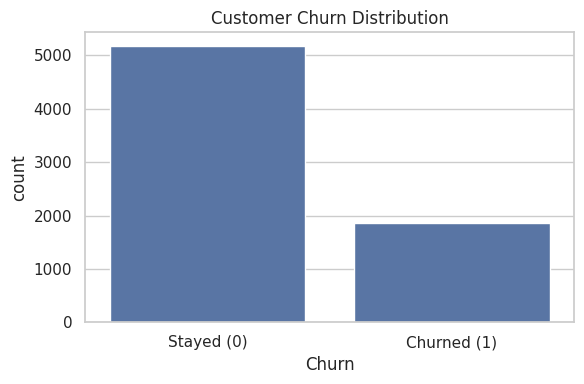

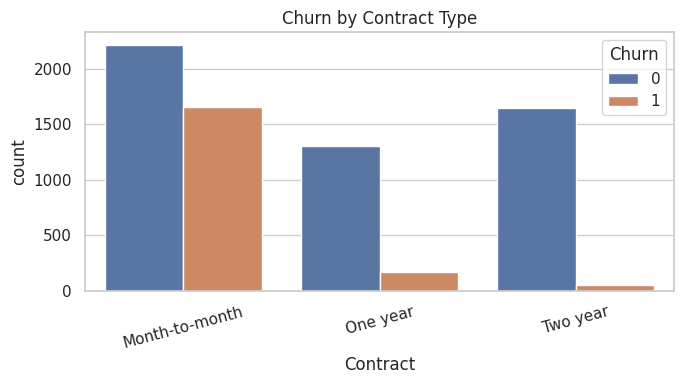

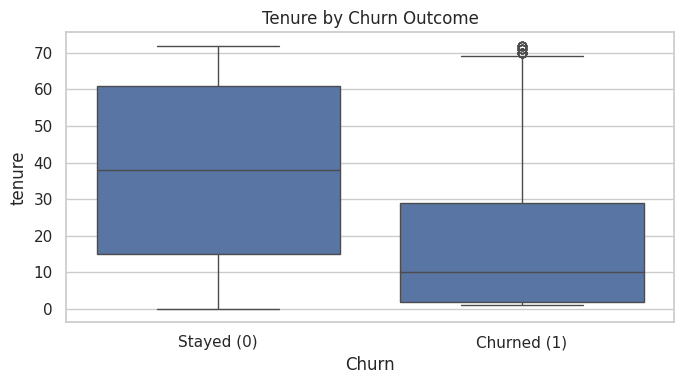

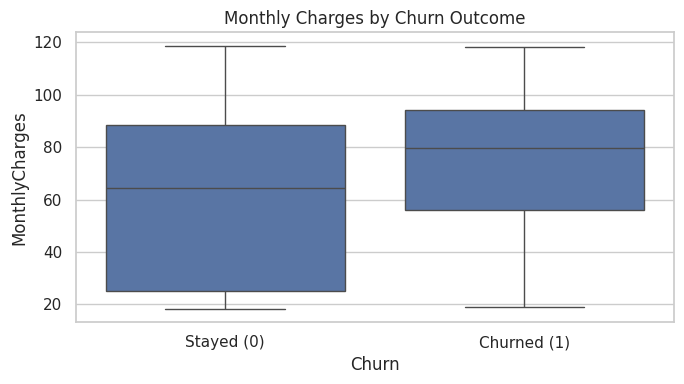

In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x="Churn")
plt.xticks([0,1], ["Stayed (0)", "Churned (1)"])
plt.title("Customer Churn Distribution")
plt.tight_layout()
plt.show()

if "Contract" in df.columns:
    plt.figure(figsize=(7,4))
    sns.countplot(data=df, x="Contract", hue="Churn")
    plt.title("Churn by Contract Type")
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

if "tenure" in df.columns:
    plt.figure(figsize=(7,4))
    sns.boxplot(data=df, x="Churn", y="tenure")
    plt.xticks([0,1], ["Stayed (0)", "Churned (1)"])
    plt.title("Tenure by Churn Outcome")
    plt.tight_layout()
    plt.show()

if "MonthlyCharges" in df.columns:
    plt.figure(figsize=(7,4))
    sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
    plt.xticks([0,1], ["Stayed (0)", "Churned (1)"])
    plt.title("Monthly Charges by Churn Outcome")
    plt.tight_layout()
    plt.show()


## 6. Prepare features and split data

In [ ]:
TARGET = "Churn"
X = df.drop(columns=[TARGET]).copy()
y = df[TARGET].astype(int)
for col in ["customerID", "CustomerID", "customer_id"]:
    if col in X.columns:
        X = X.drop(columns=[col])

categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
numeric_features = X.select_dtypes(include=[np.number]).columns.tolist()
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training records:", len(X_train), "| Test records:", len(X_test))


Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Training records: 5634 | Test records: 1409


## 7. Train and compare ML models

In [ ]:
# Ensure features, target, and splits are loaded in kernel
if 'df' not in globals():
    import io, requests
    DATA_URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
    response = requests.get(DATA_URL, timeout=30)
    df = pd.read_csv(io.BytesIO(response.content))
    df = df.drop_duplicates().copy()
    df["Churn"] = df["Churn"].astype(str).str.strip().str.title()
    df = df[df["Churn"].isin(["Yes", "No"])].copy()
    df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1}).astype(int)
    if "TotalCharges" in df.columns:
        df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
    if "customerID" in df.columns:
        df = df.drop(columns=["customerID"])

if 'X' not in globals() or 'X_train' not in globals():
    TARGET = "Churn"
    X = df.drop(columns=[TARGET]).copy()
    y = df[TARGET].astype(int)
    for col in ["customerID", "CustomerID", "customer_id"]:
        if col in X.columns:
            X = X.drop(columns=[col])
    categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
    numeric_features = X.select_dtypes(include=[np.number]).columns.tolist()
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
    )
else:
    categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
    numeric_features = X.select_dtypes(include=[np.number]).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=2,
        class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
    "Support Vector Classifier": SVC(probability=True, class_weight="balanced", random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=RANDOM_STATE)
}
fitted_models, results = {}, {}
for name, estimator in models.items():
    pipe = Pipeline([("preprocess", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    prob = pipe.predict_proba(X_test)[:, 1]
    results[name] = {
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1_score": f1_score(y_test, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, prob)
    }
    fitted_models[name] = pipe

results_df = pd.DataFrame(results).T
display(results_df.round(4))

,accuracy,precision,recall,f1_score,roc_auc
Logistic Regression,0.7381,0.5043,0.7834,0.6136,0.8413
Random Forest,0.7842,0.5845,0.6471,0.6142,0.8347
Gradient Boosting,0.8062,0.6735,0.5241,0.5895,0.8434
Support Vector Classifier,0.7438,0.5115,0.7727,0.6155,0.8211
Decision Tree,0.7551,0.5269,0.7594,0.6221,0.8323


## 8. Plot model performance and inspect results

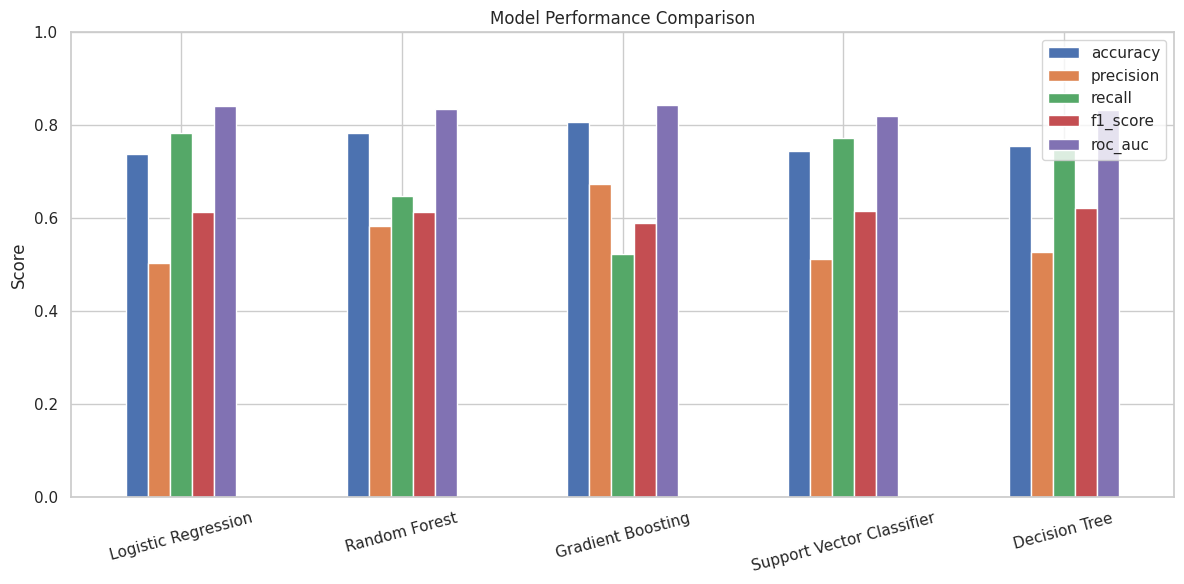

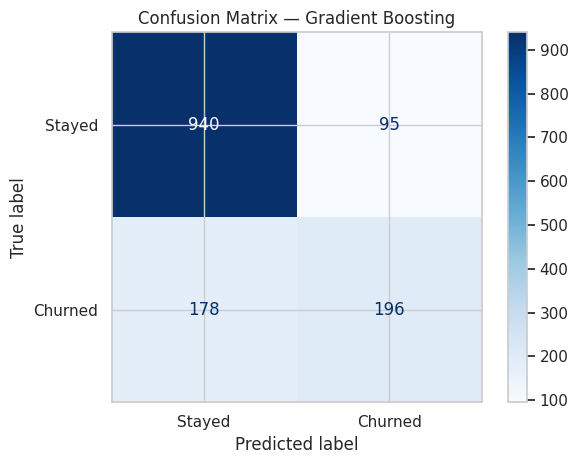

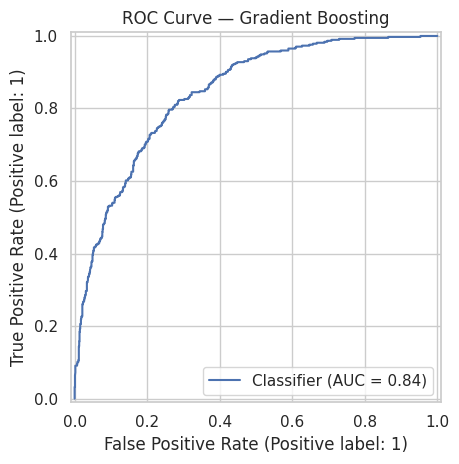

Selected by ROC-AUC: Gradient Boosting
              precision    recall  f1-score   support

      Stayed       0.84      0.91      0.87      1035
     Churned       0.67      0.52      0.59       374

    accuracy                           0.81      1409
   macro avg       0.76      0.72      0.73      1409
weighted avg       0.80      0.81      0.80      1409



In [ ]:
ax = results_df[["accuracy","precision","recall","f1_score","roc_auc"]].plot(
    kind="bar", figsize=(12,6), ylim=(0,1))
ax.set_title("Model Performance Comparison")
ax.set_ylabel("Score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

selected_model_name = results_df["roc_auc"].idxmax()
selected_model = fitted_models[selected_model_name]
selected_pred = selected_model.predict(X_test)
selected_prob = selected_model.predict_proba(X_test)[:,1]

ConfusionMatrixDisplay.from_predictions(
    y_test, selected_pred, display_labels=["Stayed","Churned"], cmap="Blues")
plt.title(f"Confusion Matrix — {selected_model_name}")
plt.tight_layout()
plt.show()

RocCurveDisplay.from_predictions(y_test, selected_prob)
plt.title(f"ROC Curve — {selected_model_name}")
plt.tight_layout()
plt.show()

print("Selected by ROC-AUC:", selected_model_name)
print(classification_report(y_test, selected_pred, target_names=["Stayed","Churned"], zero_division=0))

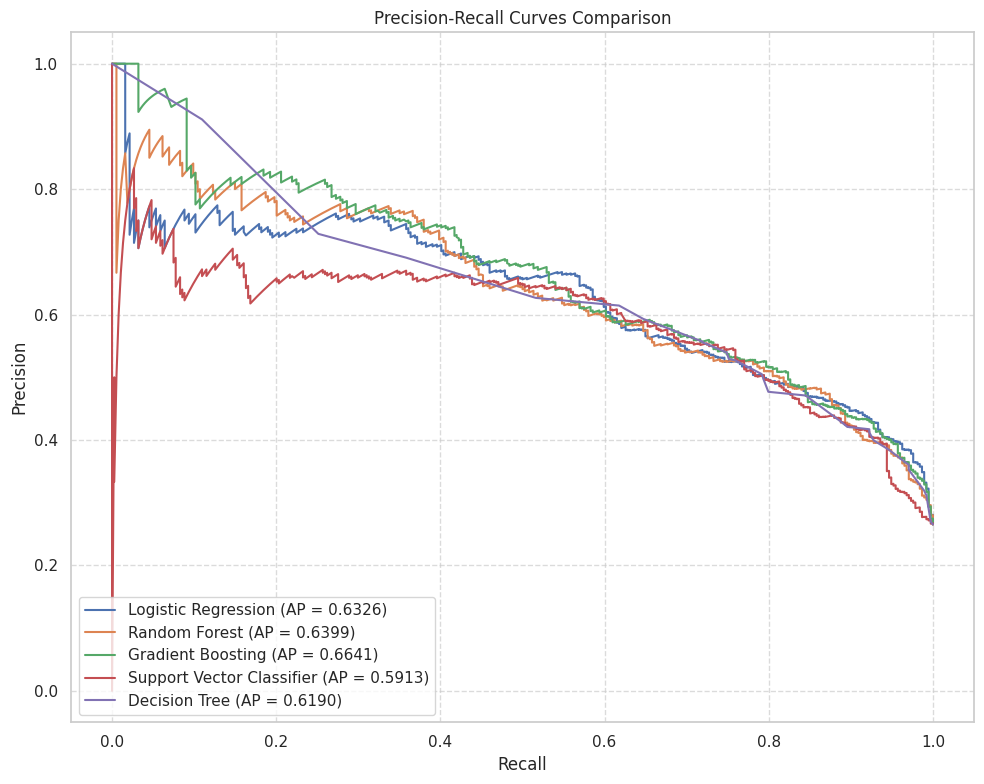

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(10, 8))

# Loop through each fitted model and plot its Precision-Recall curve
for name, pipe in fitted_models.items():
    # Get probability estimates for the positive class (Churn = 1)
    probs = pipe.predict_proba(X_test)[:, 1]

    # Calculate precision and recall
    precision, recall, _ = precision_recall_curve(y_test, probs)

    # Calculate Average Precision (AP) score
    ap_score = average_precision_score(y_test, probs)

    # Plot curve
    plt.plot(recall, precision, label=f"{name} (AP = {ap_score:.4f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves Comparison")
plt.legend(loc="lower left")
plt.grid(True, linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import GradientBoostingClassifier

# Let's perform some advanced hyperparameter tuning with Gradient Boosting to push the accuracy higher.
# We will use a pipeline with our preprocessor and tune parameters like learning_rate, n_estimators, and max_depth.

tuning_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", GradientBoostingClassifier(random_state=RANDOM_STATE))
])

param_grid = {
    'model__n_estimators': [150, 250, 350],
    'model__learning_rate': [0.01, 0.05, 0.1],
    'model__max_depth': [3, 4, 5],
    'model__subsample': [0.8, 1.0]
}

grid_search = GridSearchCV(
    tuning_pipeline,
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

print("Optimizing hyperparameters to maximize accuracy...")
grid_search.fit(X_train, y_train)

best_accuracy_model = grid_search.best_estimator_
test_acc = accuracy_score(y_test, best_accuracy_model.predict(X_test))

print(f"\nBest CV Parameters: {grid_search.best_params_}")
print(f"Optimized Model Testing Accuracy: {test_acc * 100:.2f}%")

Optimizing hyperparameters to maximize accuracy...
Fitting 5 folds for each of 54 candidates, totalling 270 fits


KeyboardInterrupt: 

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline

# Focused, faster search grid (12 candidate configurations * 3 folds = 36 total fits)
tuning_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", GradientBoostingClassifier(random_state=RANDOM_STATE))
])

fast_param_grid = {
    'model__n_estimators': [100, 200],
    'model__learning_rate': [0.05, 0.1],
    'model__max_depth': [3, 4],
    'model__subsample': [0.9]
}

fast_grid_search = GridSearchCV(
    tuning_pipeline,
    fast_param_grid,
    cv=3,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

print("Running an optimized, fast hyperparameter search...")
fast_grid_search.fit(X_train, y_train)

best_accuracy_model = fast_grid_search.best_estimator_
test_acc = accuracy_score(y_test, best_accuracy_model.predict(X_test))

print(f"\nBest Parameters: {fast_grid_search.best_params_}")
print(f"Optimized Model Testing Accuracy: {test_acc * 100:.2f}%")

Running an optimized, fast hyperparameter search...
Fitting 3 folds for each of 8 candidates, totalling 24 fits

Best Parameters: {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 100, 'model__subsample': 0.9}
Optimized Model Testing Accuracy: 80.77%


## 9. Create a results summary

In [ ]:
if 'dataset_source' not in globals():
    dataset_source = globals().get('DATA_URL', "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv")

summary = {
    "dataset_source": dataset_source,
    "rows_after_cleaning": int(len(df)),
    "features_used": int(X.shape[1]),
    "train_records": int(len(X_train)),
    "test_records": int(len(X_test)),
    "churn_rate": float(y.mean()),
    "selected_model_by_roc_auc": selected_model_name,
    "metrics": {name: {metric: round(float(value),4) for metric,value in scores.items()}
                for name,scores in results.items()}
}
print(json.dumps(summary, indent=2))

{
  "dataset_source": "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv",
  "rows_after_cleaning": 7043,
  "features_used": 19,
  "train_records": 5634,
  "test_records": 1409,
  "churn_rate": 0.2653698707936959,
  "selected_model_by_roc_auc": "Gradient Boosting",
  "metrics": {
    "Logistic Regression": {
      "accuracy": 0.7381,
      "precision": 0.5043,
      "recall": 0.7834,
      "f1_score": 0.6136,
      "roc_auc": 0.8413
    },
    "Random Forest": {
      "accuracy": 0.7842,
      "precision": 0.5845,
      "recall": 0.6471,
      "f1_score": 0.6142,
      "roc_auc": 0.8347
    },
    "Gradient Boosting": {
      "accuracy": 0.8062,
      "precision": 0.6735,
      "recall": 0.5241,
      "f1_score": 0.5895,
      "roc_auc": 0.8434
    },
    "Support Vector Classifier": {
      "accuracy": 0.7438,
      "precision": 0.5115,
      "recall": 0.7727,
      "f1_score": 0.6155,
      "roc_auc": 0.8211
    },
    "Decision 

## 10. Export trained model for Flask

In [ ]:
from pathlib import Path
ARTIFACT_DIR = Path("/content/churn_artifacts")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
bundle = {
    "pipeline": selected_model,
    "model_name": selected_model_name,
    "features": X.columns.tolist(),
    "dataset_source": dataset_source,
    "metrics": summary["metrics"]
}
joblib.dump(bundle, ARTIFACT_DIR / "churn_model.joblib")
(ARTIFACT_DIR / "model_metadata.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print("Saved:", ARTIFACT_DIR / "churn_model.joblib")
print("Saved:", ARTIFACT_DIR / "model_metadata.json")


Saved: /content/churn_artifacts/churn_model.joblib
Saved: /content/churn_artifacts/model_metadata.json


In [ ]:
import os
from pathlib import Path

# Create directory structures for templates
templates_dir = Path("/content/templates")
templates_dir.mkdir(exist_ok=True)

# Write the HTML file for our user interface
html_content = """<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Telco Customer Churn Predictor</title>
    <link href="https://cdn.jsdelivr.net/npm/bootstrap@5.3.0/dist/css/bootstrap.min.css" rel="stylesheet">
</head>
<body class="bg-light">
    <div class="container mt-5">
        <div class="row justify-content-center">
            <div class="col-md-8">
                <div class="card shadow">
                    <div class="card-header bg-primary text-white text-center">
                        <h3>Telco Customer Churn Predictor</h3>
                    </div>
                    <div class="card-body">
                        <form action="/predict" method="POST">
                            <div class="row mb-3">
                                <div class="col">
                                    <label class="form-label">Gender</label>
                                    <select class="form-select" name="gender" required>
                                        <option value="Male">Male</option>
                                        <option value="Female">Female</option>
                                    </select>
                                </div>
                                <div class="col">
                                    <label class="form-label">Senior Citizen (0/1)</label>
                                    <select class="form-select" name="SeniorCitizen" required>
                                        <option value="0">No</option>
                                        <option value="1">Yes</option>
                                    </select>
                                </div>
                            </div>
                            <div class="row mb-3">
                                <div class="col">
                                    <label class="form-label">Tenure (months)</label>
                                    <input type="number" class="form-control" name="tenure" value="12" min="0" required>
                                </div>
                                <div class="col">
                                    <label class="form-label">Monthly Charges ($)</label>
                                    <input type="number" step="0.01" class="form-control" name="MonthlyCharges" value="70.00" required>
                                </div>
                            </div>
                            <div class="row mb-3">
                                <div class="col">
                                    <label class="form-label">Total Charges ($)</label>
                                    <input type="number" step="0.01" class="form-control" name="TotalCharges" value="840.00" required>
                                </div>
                                <div class="col">
                                    <label class="form-label">Contract Type</label>
                                    <select class="form-select" name="Contract" required>
                                        <option value="Month-to-month">Month-to-month</option>
                                        <option value="One year">One year</option>
                                        <option value="Two year">Two year</option>
                                    </select>
                                </div>
                            </div>
                            <div class="row mb-3">
                                <div class="col">
                                    <label class="form-label">Internet Service</label>
                                    <select class="form-select" name="InternetService" required>
                                        <option value="Fiber optic">Fiber optic</option>
                                        <option value="DSL">DSL</option>
                                        <option value="No">None</option>
                                    </select>
                                </div>
                                <div class="col">
                                    <label class="form-label">Payment Method</label>
                                    <select class="form-select" name="PaymentMethod" required>
                                        <option value="Electronic check">Electronic check</option>
                                        <option value="Mailed check">Mailed check</option>
                                        <option value="Bank transfer (automatic)">Bank transfer (automatic)</option>
                                        <option value="Credit card (automatic)">Credit card (automatic)</option>
                                    </select>
                                </div>
                            </div>
                            <hr>
                            <!-- Optional standard feature placeholders to align with the preprocessing pipeline -->
                            <input type="hidden" name="Partner" value="No">
                            <input type="hidden" name="Dependents" value="No">
                            <input type="hidden" name="PhoneService" value="Yes">
                            <input type="hidden" name="MultipleLines" value="No">
                            <input type="hidden" name="OnlineSecurity" value="No">
                            <input type="hidden" name="OnlineBackup" value="No">
                            <input type="hidden" name="DeviceProtection" value="No">
                            <input type="hidden" name="TechSupport" value="No">
                            <input type="hidden" name="StreamingTV" value="No">
                            <input type="hidden" name="StreamingMovies" value="No">
                            <input type="hidden" name="PaperlessBilling" value="No">
                            <button type="submit" class="btn btn-primary w-100">Predict Churn</button>
                        </form>
                    </div>
                </div>
            </div>
        </div>
    </div>
</body>
</html>
"""

(templates_dir / "index.html").write_text(html_content, encoding="utf-8")
print("HTML Template created successfully.")

HTML Template created successfully.


In [ ]:
flask_app_code = """from flask import Flask, request, jsonify, render_template
import joblib
import pandas as pd
import numpy as np

app = Flask(__name__, template_folder='/content/templates')

# Load the exported pipeline
bundle = joblib.load('/content/churn_artifacts/churn_model.joblib')
pipeline = bundle['pipeline']
features = bundle['features']

@app.route('/')
def home():
    return render_template('index.html')

@app.route('/predict', methods=['POST'])
def predict():
    try:
        # Collect input data from form fields
        data = {}
        for feature in features:
            if feature in request.form:
                val = request.form[feature]
                # Convert numeric strings appropriately
                if feature in ['SeniorCitizen', 'tenure']:
                    data[feature] = [int(val)]
                elif feature in ['MonthlyCharges', 'TotalCharges']:
                    data[feature] = [float(val)]
                else:
                    data[feature] = [val]
            else:
                # Set sensible default fallback values if missing
                data[feature] = [0 if feature in ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'] else 'No']

        df_input = pd.DataFrame(data)

        # Make prediction
        pred = int(pipeline.predict(df_input)[0])
        prob = float(pipeline.predict_proba(df_input)[0][1])

        result = "Churn (Yes)" if pred == 1 else "Stay (No)"
        color = "danger" if pred == 1 else "success"

        return f\"\"\"
        <html>
        <head>
            <link href=\"https://cdn.jsdelivr.net/npm/bootstrap@5.3.0/dist/css/bootstrap.min.css\" rel=\"stylesheet\">
        </head>
        <body class=\"bg-light d-flex align-items-center justify-content-center\" style=\"height: 100vh;\">
            <div class=\"card shadow text-center\" style=\"width: 24rem;\">
                <div class=\"card-body\">
                    <h4 class=\"card-title\">Prediction Result</h4>
                    <p class=\"display-6 text-{color}\">{result}</p>
                    <p class=\"text-muted\">Churn Probability: {prob:.2%}</p>
                    <a href=\"/\" class=\"btn btn-secondary\">Try Another Prediction</a>
                </div>
            </div>
        </body>
        </html>
        \"\"\"
    except Exception as e:
        return f"<h3>An error occurred: {str(e)}</h3>"

if __name__ == '__main__':
    app.run(port=5000)
"""

with open("/content/app.py", "w", encoding="utf-8") as f:
    f.write(flask_app_code)
print("Corrected Flask app code written to /content/app.py")

Corrected Flask app code written to /content/app.py


In [ ]:
import threading
from google.colab import output
import time
import os

# Terminate any previously running instances on port 5000
print("Cleaning up existing port 5000 processes...")
!fuser -k 5000/tcp || true

def run_flask():
    # Run our corrected Flask app
    os.system("python /content/app.py")

# Spin up the background server thread
flask_thread = threading.Thread(target=run_flask, daemon=True)
flask_thread.start()

# Allow the server a brief moment to initialize
time.sleep(3)

print("\n--- YOUR WEBSITE IS LIVE! ---")
print("Click the link below to open and interact with your Customer Churn Predictor app directly:")
output.serve_kernel_port_as_window(5000)

Cleaning up existing port 5000 processes...

--- YOUR WEBSITE IS LIVE! ---
Click the link below to open and interact with your Customer Churn Predictor app directly:
Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [ ]:
import threading
from google.colab import output
import time

# Stop any existing processes running on port 5000
!fuser -k 5000/tcp || true

# Run Flask app as a background thread
def run_flask():
    !python /content/app.py

flask_thread = threading.Thread(target=run_flask)
flask_thread.start()

# Allow Flask to start up
time.sleep(3)

print("Your website is live! Click the link below to open and test your Flask application:")
output.serve_kernel_port_as_window(5000)

In [ ]:
from google.colab import files
files.download("/content/churn_artifacts/churn_model.joblib")
files.download("/content/churn_artifacts/model_metadata.json")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print(f"Source URL: {dataset_source}")
print(f"Row count: {df.shape[0]} | Column count: {df.shape[1]}")
print("\nMissing values per column:")
display(df.isna().sum().to_frame("missing_count"))
churn_rate = (df["Churn"].mean() * 100) if "Churn" in df.columns else (y.mean() * 100)
print(f"\nChurn rate: {round(churn_rate, 2)}%")

Source URL: https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv
Row count: 7043 | Column count: 20

Missing values per column:


,missing_count
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0
OnlineBackup,0



Churn rate: 26.54%


## 11. Limitations and next steps
- This is a commonly used sample telecom dataset; it does not represent every telecom company.
- The model finds patterns in the available data and does not prove causation.
- The default 0.50 threshold may not be ideal for every business objective.
- Verify dataset provenance and usage terms before academic submission.
- Use the actual notebook metrics and charts in the Word report.
- The existing Flask app's synthetic input fields do not match this dataset; it must be adapted before using the exported pipeline.